# GMI Savings Tracker: a walkthrough from the published tables

This notebook follows the analysis end to end using **only the published tables** in `site_data/` (the same files the site and the data release use). It does not read the warehouse and it does not refit any model, with one stated exception: section 5 rebuilds the area forecast from its three published inputs to show the range calibration, using the pipeline's own code.

Rules it keeps: every number in the text is computed in a cell; fiscal years end June 30; reported savings, payment evidence and leads are kept apart; budget years are plans, not outcomes.

In [1]:
import sys
from pathlib import Path
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "pyproject.toml").is_file())
sys.path.insert(0, str(root))
%matplotlib inline
import pandas as pd
from src import published as P
from src.pipeline import overview_figures as V
pd.options.display.float_format = "{:,.2f}".format
info = P.run_info()
info

{'export': '20261113T180346Z',
 'run_id': '20261113T180346Z',
 'started_utc': '2026-11-13T18:03:46+00:00',
 'checks': 143,
 'passed': 143,
 'warnings': 0,
 'failed': 0,
 'tables': 75}

## 1. Where the data came from
Six datasets from the Maryland Open Data Portal. Each load is compared with the portal's own row count.

In [2]:
src = P.load("sources")
print(f"{len(src)} sources, {info['tables']} published tables, export {info['export']}")
src.head(8)

6 sources, 75 published tables, export 20261113T180346Z


,source,dataset_id,title,use,portal_name,portal_updated,rows_portal,rows_downloaded,years,reconciled,mismatch_notes
0,payments,7syw-q4cy,State of Maryland Payments Data,"All payments by state agencies to businesses, ...",State of Maryland Payments Data: FY2008 to FY2024,2026-11-09,412880,412880,FY2008-FY2027,1,Row count and yearly totals match the portal. ...
1,budget,yu65-jmmv,Maryland Operating Budget,"Operating budget and actuals by agency, progra...",Maryland Operating Budget (current),2026-08-10,741957,741957,FY2017-FY2027,1,Row count and yearly totals match the portal. ...
2,fund,gy87-e27x,Maryland Operating Budget - Funding Source,Operating budget by fund type and fund source,Maryland Operating Budget - Funding Source,2026-08-10,26178,26178,FY2017-FY2027,1,Row count and yearly totals match the portal. ...
3,fte,x8qy-486w,State of Maryland Full Time Equivalents,Budgeted full-time-equivalent positions by age...,State of Maryland Full Time Equivalents,2026-08-10,6026,6026,FY2017-FY2027,1,Row count and yearly totals match the portal. ...
4,grants,absk-avps,State of Maryland Grant and Loan Data,State aid grants (from FY2009) and loans (from...,State of Maryland Grant and Loan Data: FY2009 ...,2026-10-09,23085,23085,FY2009-FY2025,1,Row count and yearly totals match the portal. ...
5,highered,4mca-332u,Maryland Operating Budget: CUR and CR,Operating budget of public higher education (M...,Maryland Operating Budget: CUR and CR,2026-08-10,84446,84446,FY2017-FY2027,1,Row count and yearly totals match the portal. ...


## 2. The checks
A build that fails a stop check keeps the last good database and exports nothing. The warning in this run is the forecast range coverage, taken up in section 5.

{'pass': 143}


,stage,check,status,detail


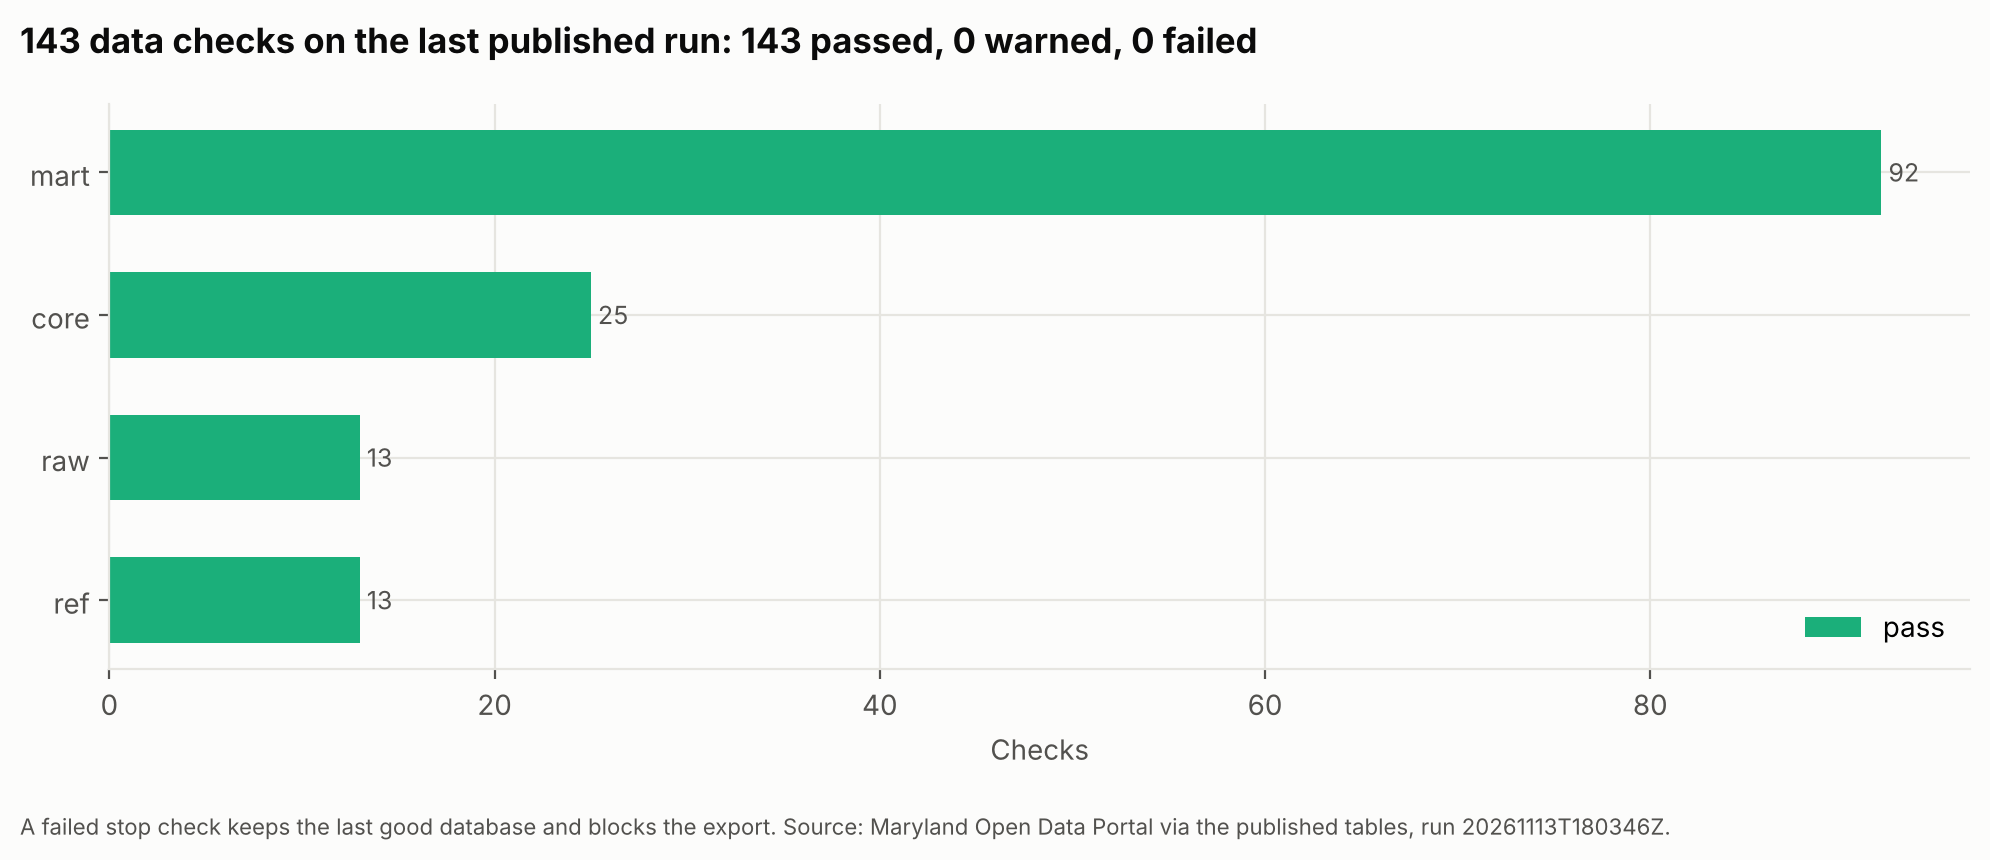

In [3]:
chk = P.load("run_checks")
print(chk.status.value_counts().to_dict())
display(chk[chk.status != "pass"][["stage", "check", "status", "detail"]])
V.checks();

## 3. The spending base
Controllable purchases in the operating budget: the part of spending the savings work can act on. Hatched years are budgets.

Last actual year FY2025: $4.1B of controllable purchases


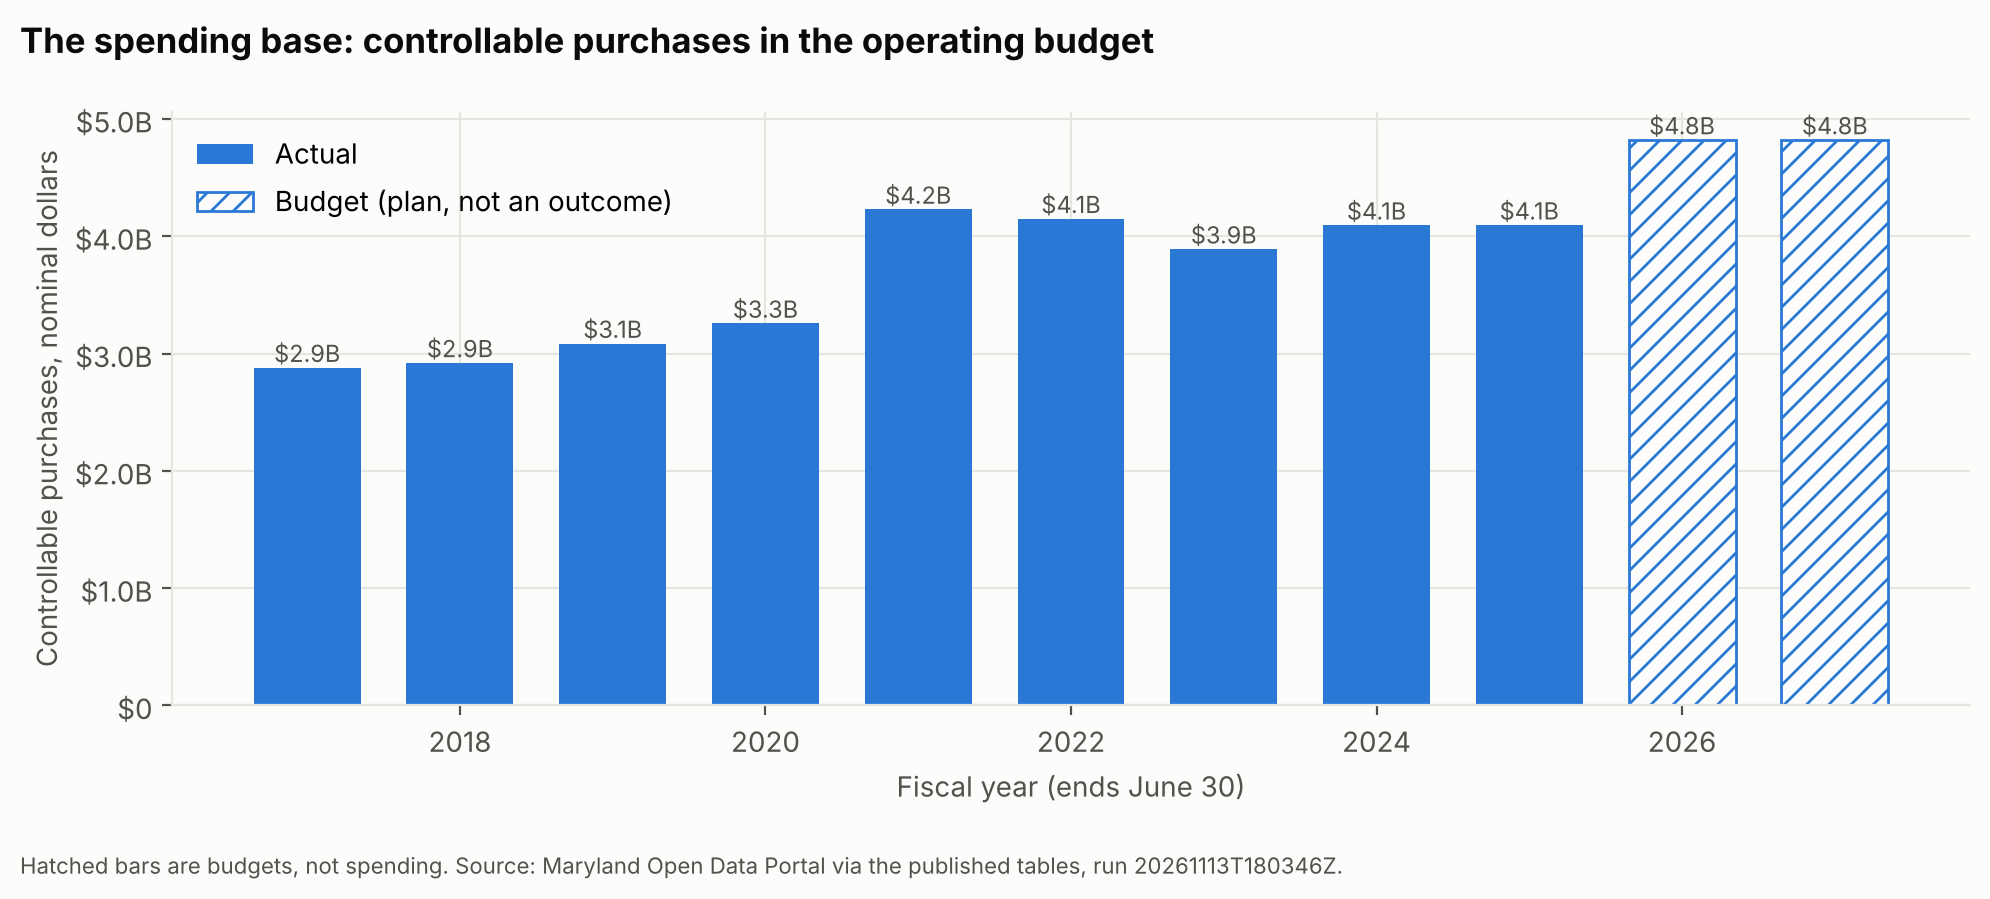

In [4]:
s = P.load("f_scope")
base = s[s.scope == "Controllable purchases"].groupby(["fiscal_year", "stage"]).budget.sum().reset_index()
last = base[base.stage == "Actual"].iloc[-1]
print(f"Last actual year FY{int(last.fiscal_year)}: {V.money(last.budget)} of controllable purchases")
V.spending_base();

## 4. Reported savings against the State's own payments
GMI reported savings items; the tracker pairs each with the payments that would show it. A fall in payments is evidence, not proof (correlation, not cause), and an item with no visible change is 'not seen yet', not 'false'.

,items,reported
status,,
Not seen yet,2,"18,800,000.00"
Payments did not fall,3,0.00
Payments fell,2,0.00
Projected only,2,0.00
Seen,3,"11,500,000.00"


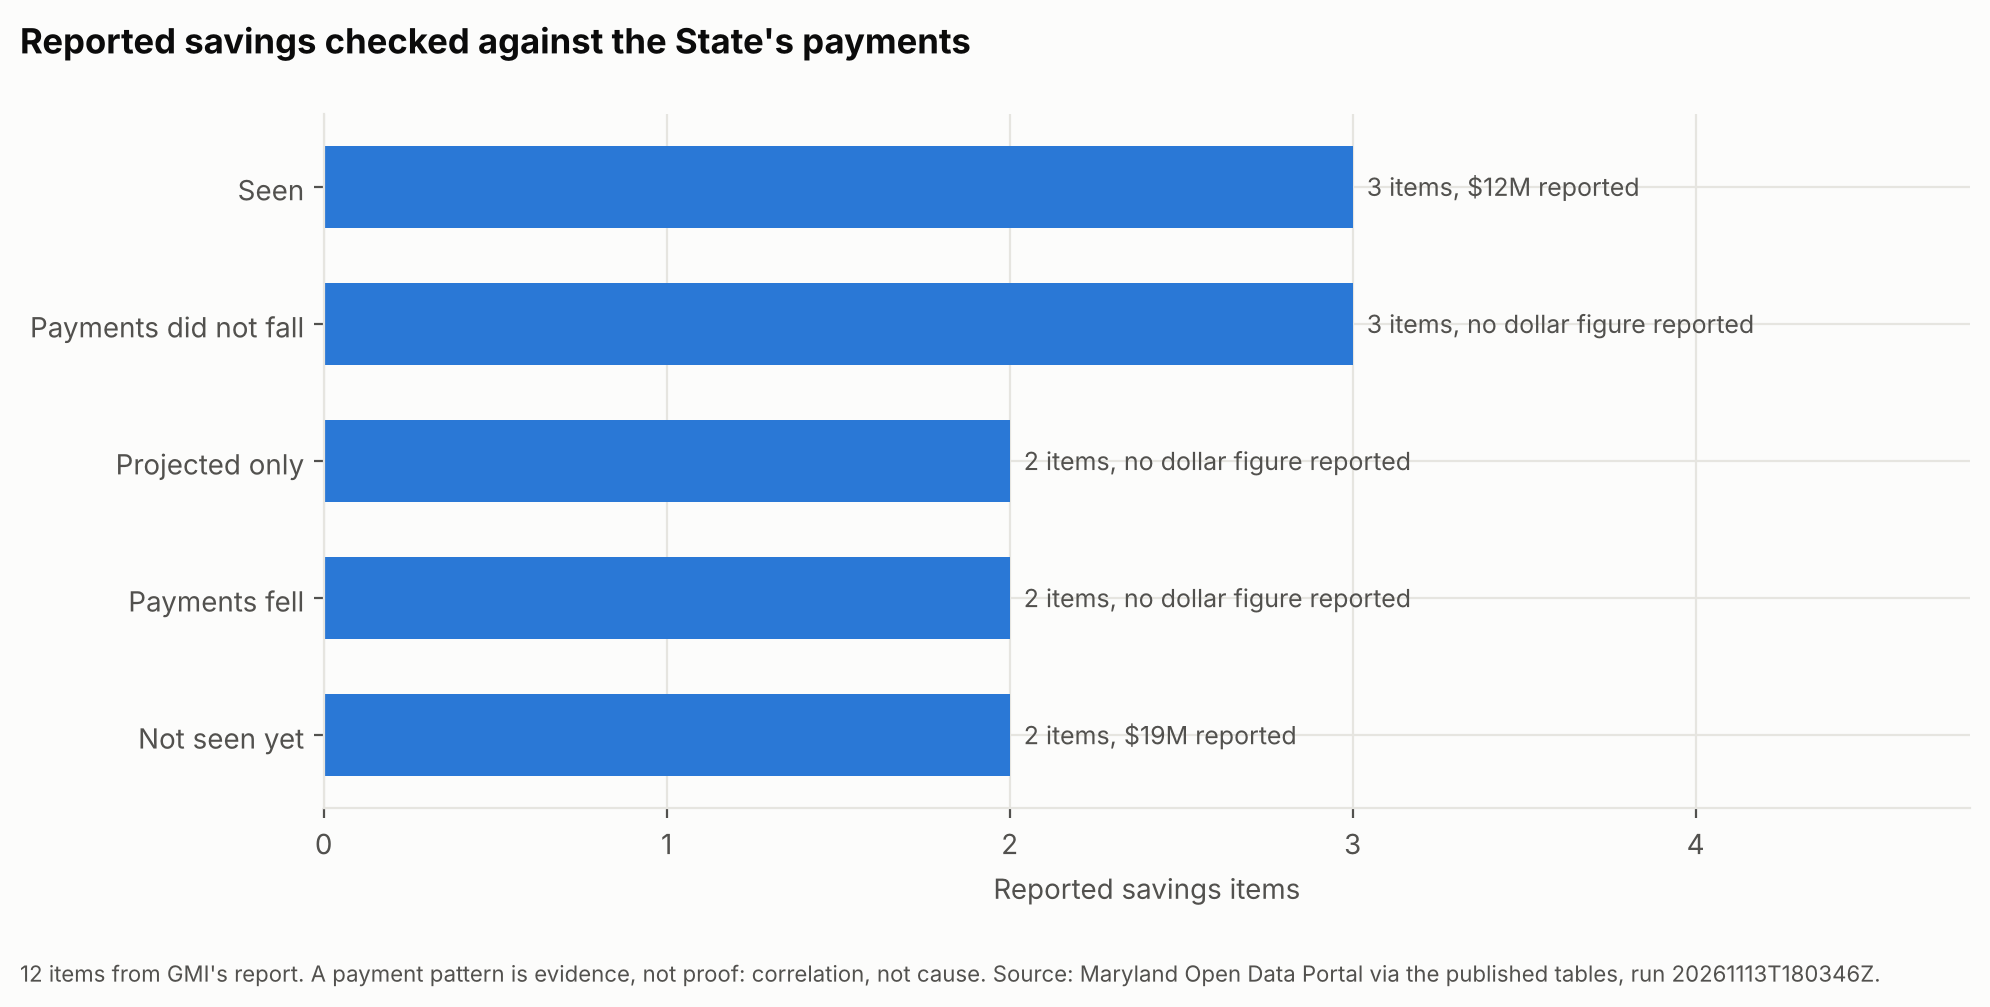

In [5]:
st = P.load("d_savings_status")
display(st.groupby("status").agg(items=("check_id", "size"), reported=("reported", "sum")))
V.savings_status();

## 5. Forecasts, and how far to trust their ranges
Each focus area gets the simplest model that wins a rolling backtest (naive in most areas). The published range is the 10th to 90th percentile of bootstrap paths, a nominal 80% range. The backtest shows it is too narrow, so a calibrated range is added beside it: the raw range stretched around the median by a conformal factor fitted on past misses. The raw columns are unchanged.

The next cell rebuilds the forecast from the published `f_code`, `f_scope` and `f_fund` and confirms it equals the published `f_forecast` before anything is shown.

In [6]:
from src.models import forecast_published as FP
tables = V.rebuilt()
diffs = FP.differences(tables)
assert not diffs, diffs
print("rebuild equals the published forecast:", len(tables["f_forecast"]), "rows")
display(P.load("d_forecast_model")[["area", "method", "growth", "baseline_fy2025"]])
cov = V.coverage_summary()
cov

rebuild equals the published forecast: 105 rows


,area,method,growth,baseline_fy2025
0,Fleet & fuel,Naive (last actual),0.04,"193,100,466.00"
1,"IT hardware, software & services",Naive (last actual),0.10,"692,249,948.00"
2,Other controllable purchases,Naive (last actual),0.05,"2,806,136,520.00"
3,"Print, copy & mail",Naive (last actual),0.00,"52,438,200.00"
4,Real estate & leases,Log-linear trend,0.01,"141,564,622.00"
5,Telecom,Naive (last actual),0.03,"46,824,618.00"
6,Utilities & facility energy,Naive (last actual),0.03,"161,540,934.00"


,scope,calibrated,n,hits,coverage,cov_lo,cov_hi,factor
0,in_sample,0,63,40,0.63,0.51,0.74,1.00
1,in_sample,1,63,52,0.83,0.71,0.90,1.63
2,out_of_sample,0,63,37,0.59,0.46,0.70,1.00
3,out_of_sample,1,63,53,0.84,0.73,0.91,1.96
4,expanding_origin,0,42,19,0.45,0.31,0.60,1.00
5,expanding_origin,1,42,41,0.98,0.88,1.00,5.46


Raw range: 40 of 63 past outcomes inside (63.5%) against a nominal 80%.
Calibrated, each outcome year held out: 53 of 63 (84.1%; 95% interval 73% to 91%).
Calibrated, only outcomes known at the origin: 41 of 42 (97.6%), mean factor 5.5: too wide, because early origins had few misses to fit on.


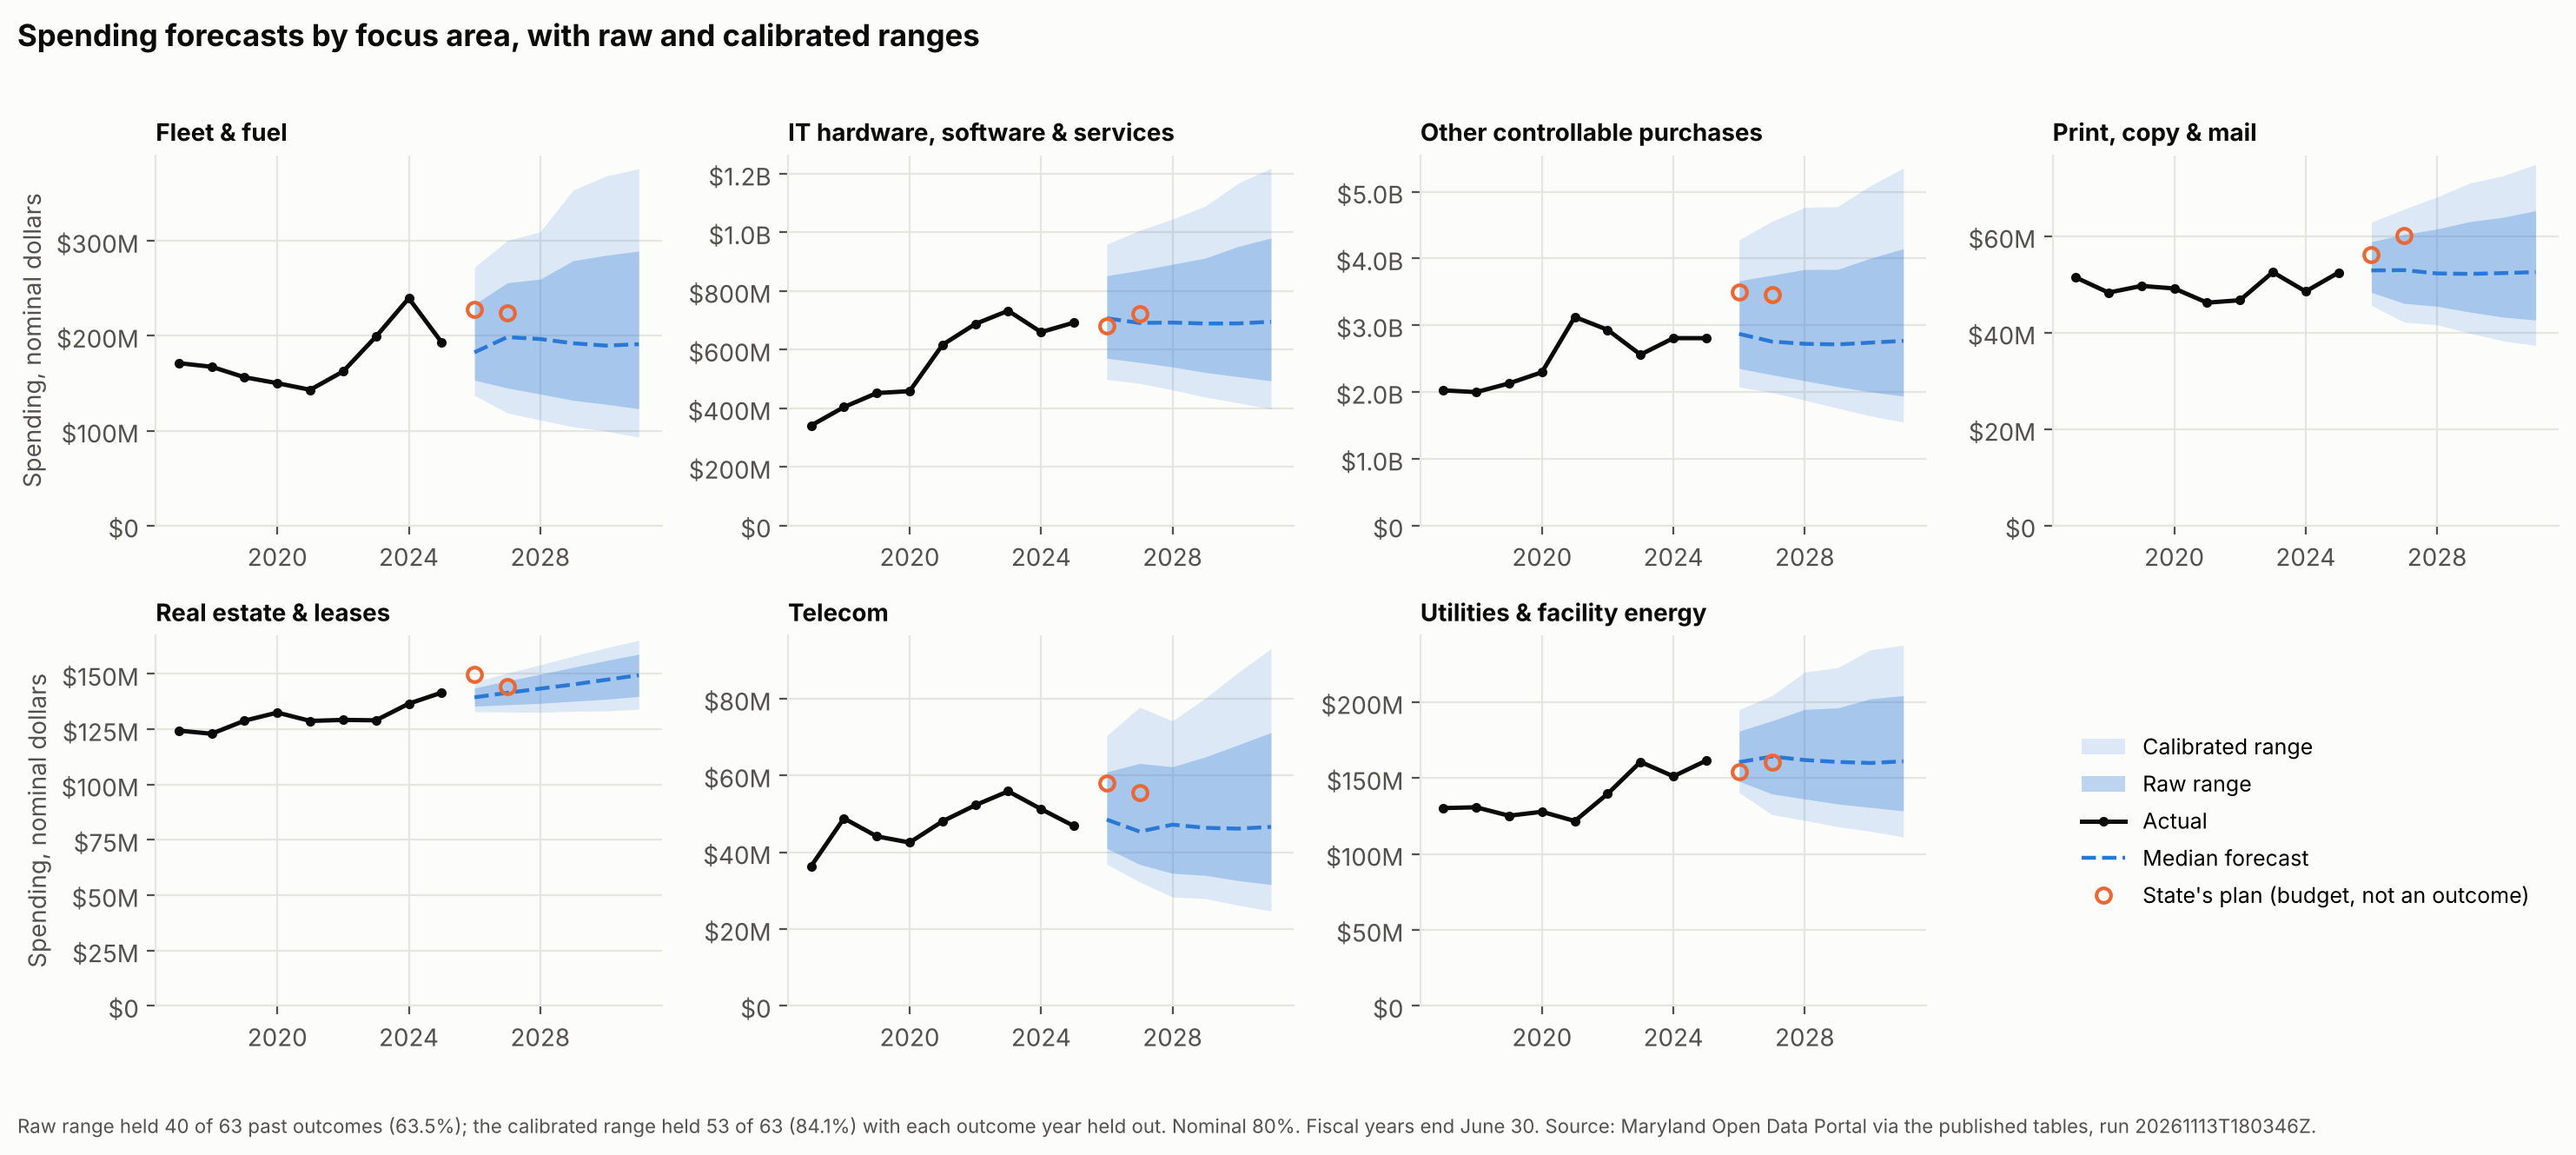

In [7]:
r = cov[(cov.scope == "in_sample") & (cov.calibrated == 0)].iloc[0]
k = cov[(cov.scope == "out_of_sample") & (cov.calibrated == 1)].iloc[0]
e = cov[(cov.scope == "expanding_origin") & (cov.calibrated == 1)].iloc[0]
print(f"Raw range: {int(r.hits)} of {int(r.n)} past outcomes inside ({r.coverage:.1%}) against a nominal 80%.")
print(f"Calibrated, each outcome year held out: {int(k.hits)} of {int(k.n)} ({k.coverage:.1%}; 95% interval {k.cov_lo:.0%} to {k.cov_hi:.0%}).")
print(f"Calibrated, only outcomes known at the origin: {int(e.hits)} of {int(e.n)} ({e.coverage:.1%}), mean factor {e.factor:.1f}: too wide, because early origins had few misses to fit on.")
V.forecast_fan();

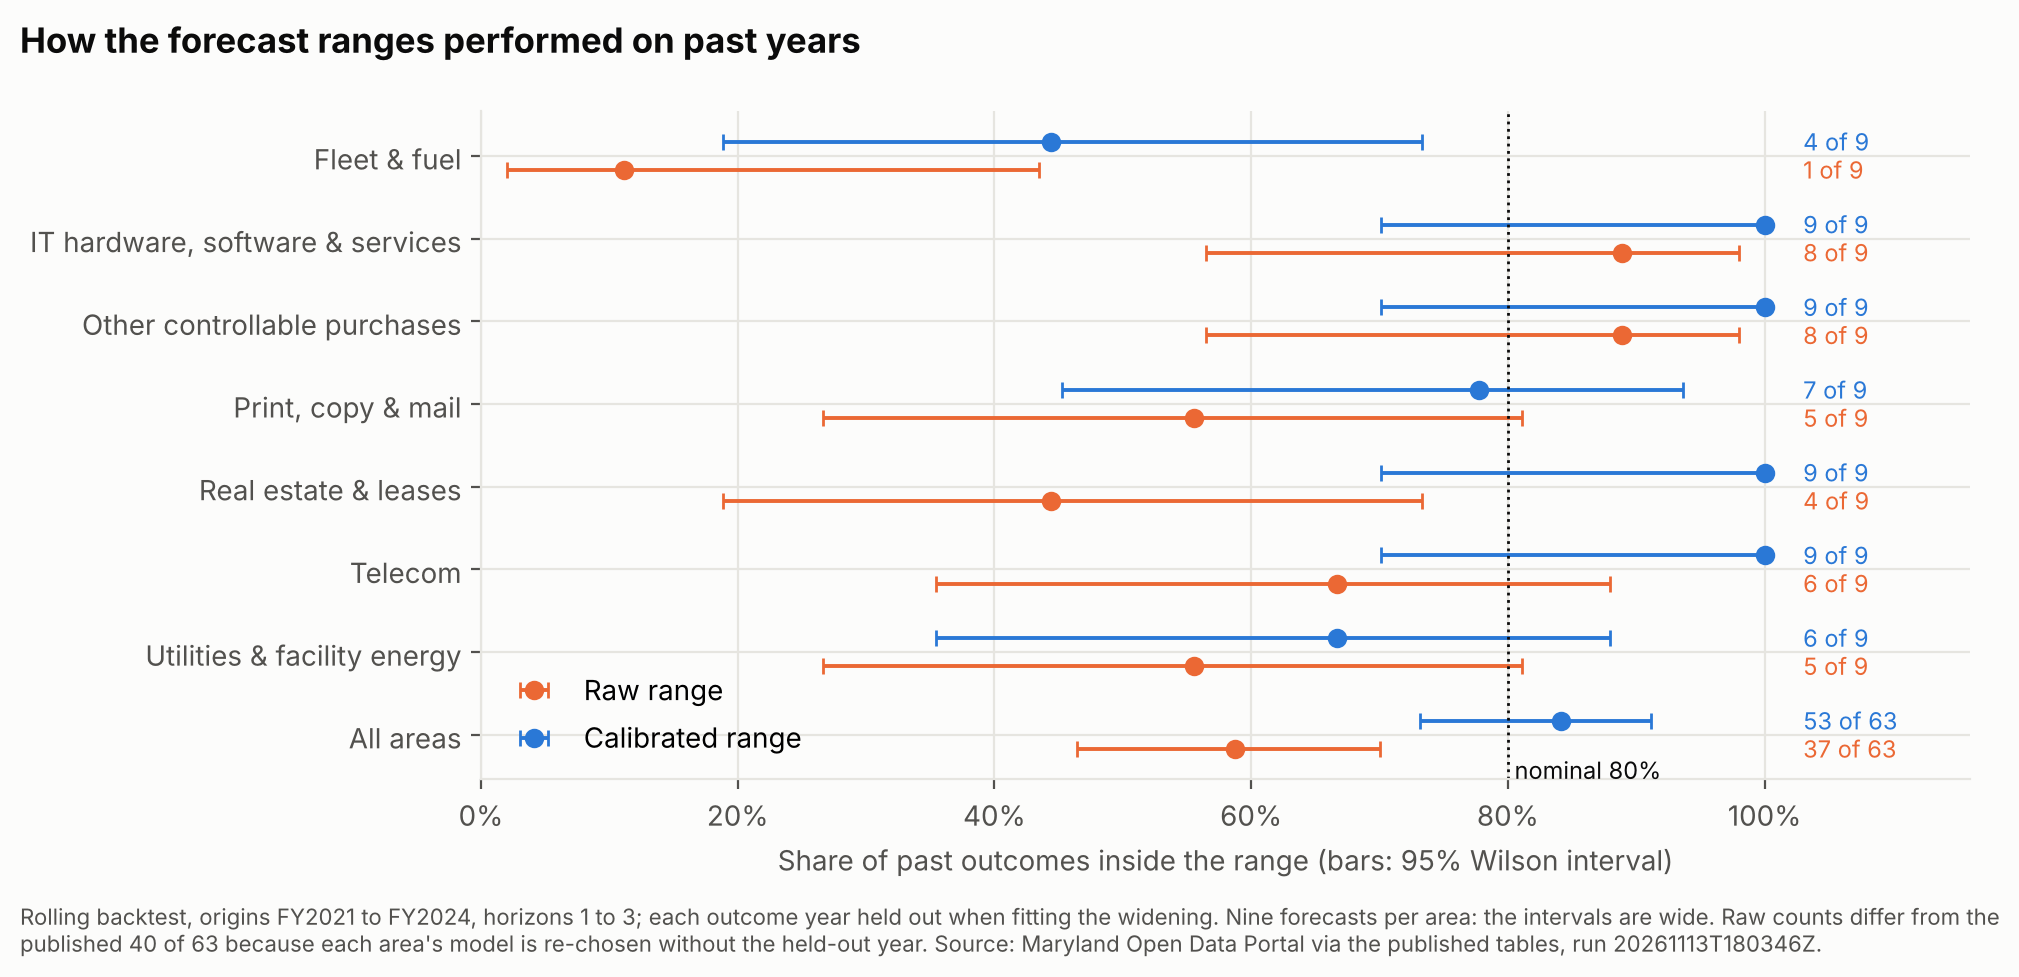

In [8]:
V.range_coverage();

**Reading it.** Held out by year, the calibrated range covers about what it claims, and the interval around that figure contains 80%. It is a pooled correction: Fleet & fuel stays under-covered because its model is wrong more often than a wider range can absorb. The real-time (expanding-origin) design over-covers. Sixty-three forecasts is a small sample and areas share shocks, so treat the calibrated range as a better-supported indication, not a guarantee.

The review also asked for LightGBM ranges where they cover better. The published challenger backtest shows why they are not simply swapped in: they are closer to nominal than the naive band but still short of it.

In [9]:
cb = P.load("d_challenger_backtest")
display(cb.pivot(index="origin_fy", columns="model", values="coverage_80"))
print("The tracker adopts LightGBM per agency–code series only where it beats naive in that series' own backtest; the registry and the Forecasts tab show the adopted count.")

model,LightGBM quantile (global),Naive (last actual)
origin_fy,,
2022,0.72,0.33
2023,0.74,0.44
2024,0.74,0.53


The tracker adopts LightGBM per agency–code series only where it beats naive in that series' own backtest; the registry and the Forecasts tab show the adopted count.


## 6. Opportunities: leads, not savings
Four detectors flag spending worth a look. The dollar ranges apply screening percentages to flagged spending; they are not forecasts and are not additive.

,leads,low,high
detector,,,
Growth above trend,40,"46,935,449.00","140,806,336.00"
Leverage,38,"15,655,624.00","39,139,057.00"
Peer gap,308,"45,439,125.00","148,135,468.00"
Tail spend,3,"739,265.00","2,464,215.00"


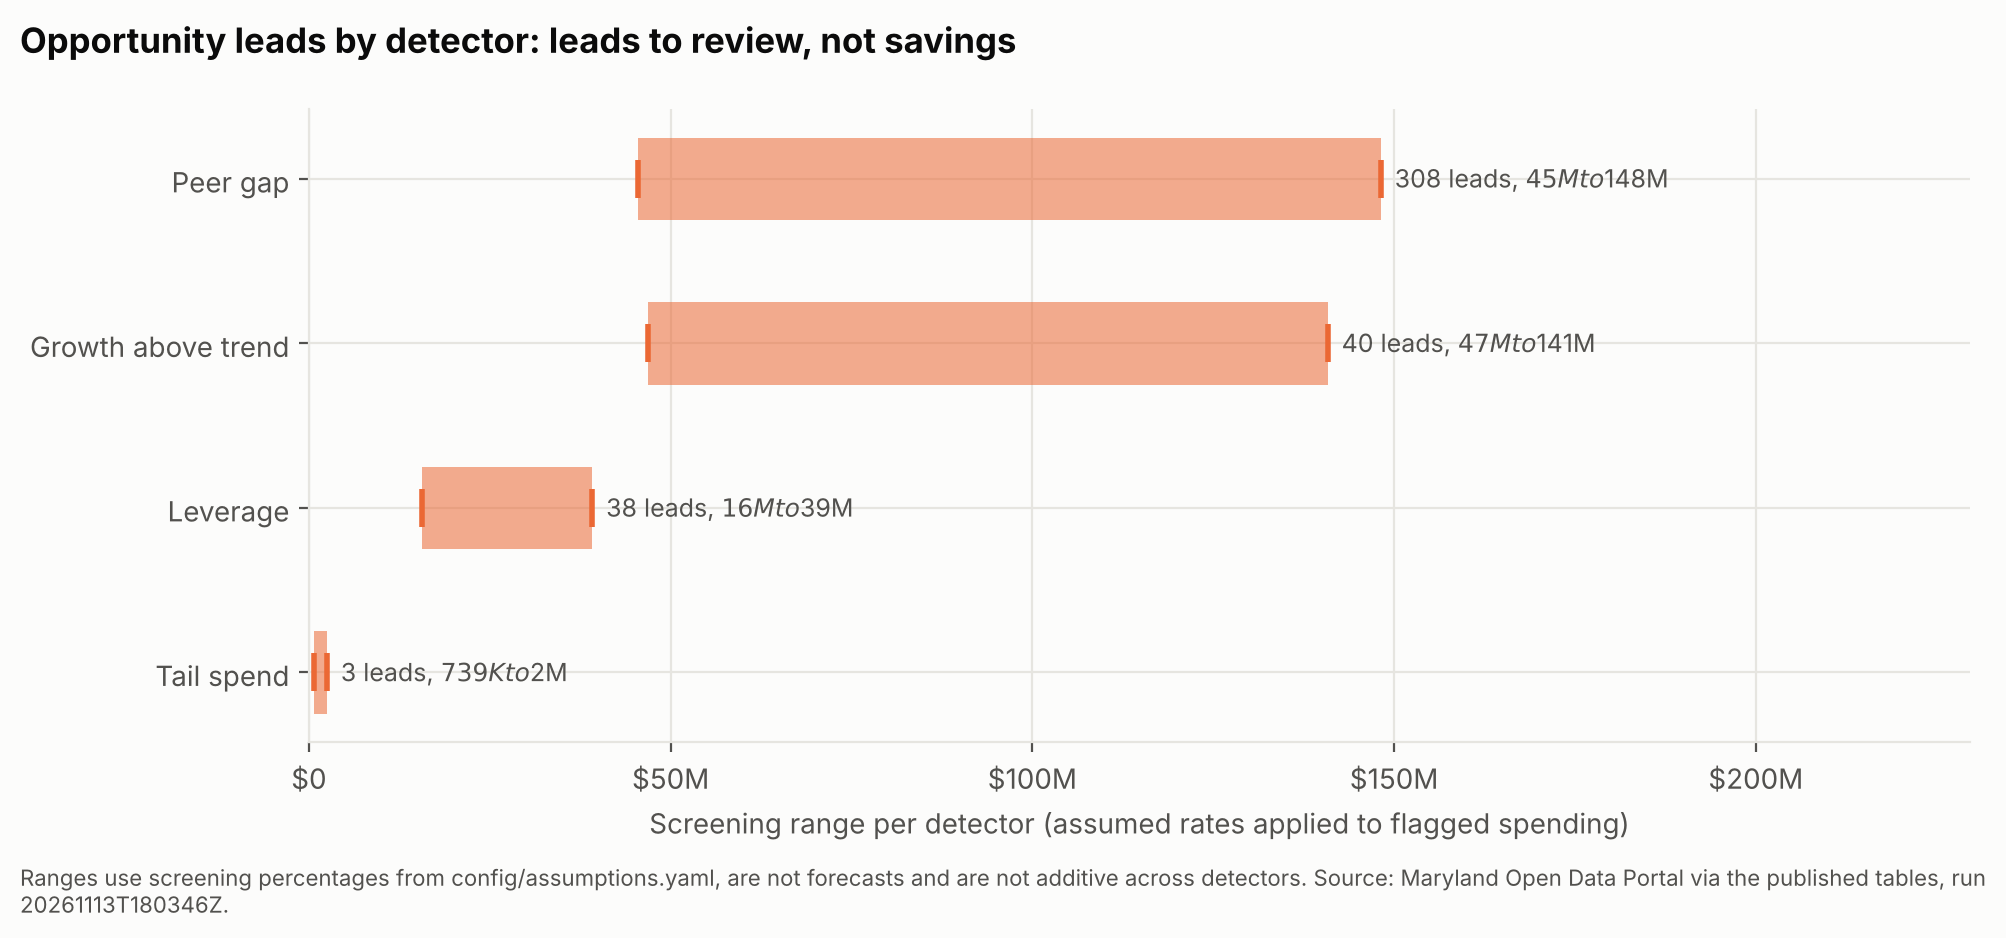

In [10]:
o = P.load("d_opps")
display(o.groupby("detector").agg(leads=("opp_id", "size"), low=("low", "sum"), high=("high", "sum")))
V.opportunities();

## 7. The path to the target
The plan table stacks reported rates and the largest leads. Each step names its basis; steps resting on assumed rates are labelled as such.

In [11]:
pl = P.load("d_plan50")
display(pl[["step", "action", "basis", "saving", "cumulative"]])
print(f"Cumulative after {len(pl)} steps: {V.money(pl.cumulative.iloc[-1])}")

,step,action,basis,saving,cumulative
0,1,Apply GMI's reported savings rates,forecast FY2027 spending × the rate GMI report...,"29,640,863.64","29,640,863.64"
1,2,Statewide contract: Carroll Independent Fuel,assumed 3.5% of $65.6M paid by 48 agencies (as...,"2,294,682.06","31,935,545.70"
2,3,Statewide contract: Carahsoft,assumed 3.5% of $57.4M paid by 38 agencies (as...,"2,009,015.21","33,944,560.91"
3,4,Statewide contract: Shi International,assumed 3.5% of $52.5M paid by 39 agencies (as...,"1,835,999.76","35,780,560.67"
4,5,Statewide contract: Wgl Energy Services,assumed 3.5% of $52.0M paid by 16 agencies (as...,"1,820,657.18","37,601,217.85"
5,6,Statewide contract: Applied Technology Services,assumed 3.5% of $43.2M paid by 33 agencies (as...,"1,510,508.14","39,111,725.98"
6,7,Statewide contract: Verizon,assumed 3.5% of $32.3M paid by 54 agencies (as...,"1,129,630.47","40,241,356.45"
7,8,Statewide contract: Strategic Communications,assumed 3.5% of $29.3M paid by 18 agencies (as...,"1,026,177.78","41,267,534.23"
8,9,Statewide contract: Element Fleet,assumed 3.5% of $26.5M paid by 48 agencies (as...,"928,825.28","42,196,359.51"
9,10,Statewide contract: Skyline Technology Solutions,assumed 3.5% of $25.6M paid by 17 agencies (as...,"896,501.50","43,092,861.01"


Cumulative after 30 steps: $53M


## 8. Limits, and how to reproduce
- Nine actual years per area. No model forecasts these series well; most MASE values are above 1.
- Ranges are calibrated on 63 pooled forecasts. Coverage by area is uneven.
- Leads have no recorded review outcome, so no hit rate is claimed for the detectors.
- The LightGBM corridor rests on three backtest origins and the revenue band on few years of history: both are indicative (see the model cards on the site's models page).

```bash
uv sync --frozen --extra dev --extra notebook      # the locked environment
python -m src.models.forecast_published --check    # rebuild the forecast from the published tables
python -m src.pipeline.overview_figures            # the figures in this notebook, as PNG
docker compose run --rm test                       # the same tests in a container
```

Method references: Hyndman and Athanasopoulos, *Forecasting: Principles and Practice* (3rd ed.), on prediction intervals and rolling-origin evaluation; Gneiting and Raftery (2007) on the interval score; Angelopoulos and Bates (2021) on conformal prediction; Wilke, *Fundamentals of Data Visualization*, on showing uncertainty.